# 04 - Stage 2 (Bagging): Random Forest

**Bagging** = *bootstrap aggregating*. Train many decision trees, each on a
random resample of the training epochs and a random subset of features, and
average their votes. A single deep tree overfits badly; averaging hundreds of
them that each overfit *differently* cancels much of that noise out.

Unlike Stage 1, a forest can model non-linear interactions - "high theta
*and* low beta *at frontal sites*" - without anyone specifying them.

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

CACHE = "data/epochs.npz"
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"

## Step 1 - Load the preprocessed epochs

**What this does.** Loads the cache written by notebook `01`: every 2-second EEG
window ("epoch"), its 456 hand-engineered features, the label, and - crucially -
the ID of the subject it came from.

**Why the subject ID matters.** Each person contributes many epochs (61 to 336
of them). If epochs from the same person landed in both training and test sets,
the model could score well by recognising the *person* rather than ADHD - the
label is constant within a subject, so recognising the subject gives the label
away. The subject ID is what lets us prevent that in Step 2.

In [2]:
if not os.path.exists(CACHE):
    raise FileNotFoundError("Run 01_Data_and_Preprocessing.ipynb first - it builds " + CACHE)

cache = np.load(CACHE, allow_pickle=True)
X_feat, y, groups = cache["Xf"], cache["y"].astype(int), cache["g"]

# Band powers span several orders of magnitude and are right-skewed; log1p
# compresses that range so no single feature dominates distance-based or
# gradient-based models. Trees are unaffected either way.
X = np.log1p(np.clip(X_feat, 0, None))
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

subj = pd.DataFrame({"ID": groups, "y": y}).groupby("ID").y.first()
print("epochs   :", X.shape[0])
print("features :", X.shape[1])
print("subjects :", len(subj), "  (%d ADHD, %d Control)" % (subj.sum(), (1 - subj).sum()))

epochs   : 16749
features : 456
subjects : 121   (61 ADHD, 60 Control)


## Step 2 - Build subject-grouped cross-validation folds

**What this does.** Splits the 121 subjects into 5 folds. Each fold holds out
about 24 *people*; all of their epochs go to the test side together.
`StratifiedGroupKFold` keeps the ADHD/Control balance similar across folds.

**Why 5 folds and not one split.** With only 121 subjects, which particular
people end up in the test set changes the score a lot. Five folds give five
estimates, and we report their mean and spread. A single split would hide that
spread entirely.

**Why there is an `assert`.** It is cheap insurance: if a future change ever
lets a subject leak across a split, the notebook stops here instead of quietly
reporting an inflated number.

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

N_SPLITS, SEED = 5, 42
cv = list(StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
          .split(X, y, groups))

for k, (tr, te) in enumerate(cv):
    assert not (set(groups[tr]) & set(groups[te])), "subject leaked across split!"
    print("fold %d: train %5d epochs / %2d subjects   test %4d epochs / %2d subjects"
          % (k, len(tr), len(set(groups[tr])), len(te), len(set(groups[te]))))
print("\nVerified: no subject appears on both sides of any fold.")

fold 0: train 13419 epochs / 97 subjects   test 3330 epochs / 24 subjects
fold 1: train 13412 epochs / 97 subjects   test 3337 epochs / 24 subjects
fold 2: train 13342 epochs / 96 subjects   test 3407 epochs / 25 subjects
fold 3: train 13413 epochs / 97 subjects   test 3336 epochs / 24 subjects
fold 4: train 13410 epochs / 97 subjects   test 3339 epochs / 24 subjects

Verified: no subject appears on both sides of any fold.


## Step 3 - Define how a model is scored

**What this does.** Two helpers used by every model notebook.

- `subject_scores` turns epoch-level predictions into one decision per person
  by **averaging that person's epoch probabilities**, then scores those
  decisions. This is the number that matters: diagnosis happens per person, not
  per 2-second window.
- `save_result` writes the 5-fold summary (and each fold's score) to
  `results.csv` / `results_folds.csv`, which notebook `07` reads.

**Why ROC-AUC alongside accuracy.** Accuracy depends on where the 0.5 cut-off
sits; ROC-AUC measures how well the model *ranks* ADHD subjects above controls,
regardless of the cut-off. Both are reported. The standard deviation is the
sample SD across the 5 folds.

In [4]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix, roc_curve

def subject_scores(g_te, y_te, p):
    """Average epoch probabilities per subject, then score the per-subject decision."""
    s = (pd.DataFrame({"ID": g_te, "y": y_te, "p": p})
         .groupby("ID").agg(y=("y", "first"), p=("p", "mean")))
    pred = (s.p > 0.5).astype(int)
    return roc_auc_score(s.y, s.p), accuracy_score(s.y, pred), f1_score(s.y, pred)

def save_result(model, stage, res, path="results.csv"):
    """Upsert one model's summary row; per-fold rows go to results_folds.csv."""
    row = dict(model=model, stage=stage, n_folds=len(res))
    for c in ("epoch_auc", "subject_auc", "subject_acc", "subject_f1"):
        row[c], row[c + "_sd"] = res[c].mean(), res[c].std()
    for p, new in ((path, pd.DataFrame([row])),
                   (path.replace(".csv", "_folds.csv"), res.assign(model=model, stage=stage))):
        try:
            old = pd.read_csv(p); old = old[old.model != model]
            new = pd.concat([old, new], ignore_index=True)
        except FileNotFoundError:
            pass
        new.sort_values(["stage", "model"]).to_csv(p, index=False)
    print("saved %s -> %s" % (model, path))

print("helpers defined")

helpers defined


## Step 4 - Define the model

**What this does.** 400 trees, each grown until leaves hold at least 2 epochs,
with balanced class weights.

**Why no `StandardScaler`.** Trees split on thresholds within one feature at a
time, so rescaling a feature changes nothing about the splits. The scaler in
Stage 1 was for logistic regression's benefit, not the data's.

**Why `min_samples_leaf=2` rather than deeper regularisation.** Random forests
are fairly robust to their settings; this keeps individual trees expressive
while stopping leaves from memorising single epochs. `n_jobs=-1` uses every
CPU core - the forest is the slowest classical model here.

In [5]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=400,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",400
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

## Step 5 - Train and evaluate across the 5 folds

**What this does.** For each fold: fit the model on the training subjects'
epochs, predict a probability of ADHD for every test epoch, then score both
per epoch and per subject. Out-of-fold predictions are kept for the plots.

**Why `clone`.** Each fold gets a fresh, unfitted copy of the model so nothing
learned on one fold carries into the next.

In [6]:
from sklearn.base import clone

rows, oof_p, oof_y, oof_g = [], [], [], []
t0 = time.time()
for k, (tr, te) in enumerate(cv):
    m = clone(model)
    m.fit(X[tr], y[tr])
    p = m.predict_proba(X[te])[:, 1]          # P(ADHD) for every test epoch

    ep_auc = roc_auc_score(y[te], p)
    s_auc, s_acc, s_f1 = subject_scores(groups[te], y[te], p)
    rows.append(dict(fold=k, epoch_auc=ep_auc, subject_auc=s_auc,
                     subject_acc=s_acc, subject_f1=s_f1))
    oof_p.append(p); oof_y.append(y[te]); oof_g.append(groups[te])
    print("fold %d  epoch-AUC %.3f | subject-AUC %.3f  subject-acc %.3f"
          % (k, ep_auc, s_auc, s_acc))

res = pd.DataFrame(rows)
oof_p, oof_y, oof_g = map(np.concatenate, (oof_p, oof_y, oof_g))
print("\nRandom Forest  -  5-fold results  (%.0f s)" % (time.time() - t0))
for c in ["epoch_auc", "subject_auc", "subject_acc", "subject_f1"]:
    print("  %-12s %.3f +- %.3f" % (c, res[c].mean(), res[c].std()))

save_result("Random Forest", "2 - Bagging", res)

fold 0  epoch-AUC 0.714 | subject-AUC 0.854  subject-acc 0.667


fold 1  epoch-AUC 0.772 | subject-AUC 0.868  subject-acc 0.667


fold 2  epoch-AUC 0.770 | subject-AUC 0.840  subject-acc 0.760


fold 3  epoch-AUC 0.675 | subject-AUC 0.660  subject-acc 0.708


fold 4  epoch-AUC 0.661 | subject-AUC 0.667  subject-acc 0.667

Random Forest  -  5-fold results  (90 s)
  epoch_auc    0.718 +- 0.052
  subject_auc  0.778 +- 0.105
  subject_acc  0.694 +- 0.041
  subject_f1   0.744 +- 0.037
saved Random Forest -> results.csv


## Step 6 - One decision per subject

**What this does.** Pools the out-of-fold predictions - every subject was in a
test fold exactly once - and makes the final per-person call by averaging that
person's epoch probabilities.

**Why the pooled numbers differ slightly from the fold means.** The fold means
average five scores each computed on about 24 people; the pooled score is
computed once on all 121. Both are legitimate; the fold mean comes with a
spread, which is why the tables quote it.

In [7]:
subject_pred = (pd.DataFrame({"ID": oof_g, "y_true": oof_y, "p": oof_p})
                .groupby("ID").agg(y_true=("y_true", "first"), p_adhd=("p", "mean")))
subject_pred["pred"] = (subject_pred.p_adhd > 0.5).astype(int)
subject_pred["correct"] = subject_pred.pred == subject_pred.y_true

print("Pooled subject-level performance (n = %d)" % len(subject_pred))
print("  accuracy : %.3f" % accuracy_score(subject_pred.y_true, subject_pred.pred))
print("  ROC-AUC  : %.3f" % roc_auc_score(subject_pred.y_true, subject_pred.p_adhd))
print("  F1       : %.3f" % f1_score(subject_pred.y_true, subject_pred.pred))

wrong = subject_pred[~subject_pred.correct].assign(margin=lambda d: (d.p_adhd - .5).abs())
print("\n%d of %d subjects misclassified. Most confident mistakes:" % (len(wrong), len(subject_pred)))
display(wrong.sort_values("margin", ascending=False).head(5).round(3))

Pooled subject-level performance (n = 121)
  accuracy : 0.694
  ROC-AUC  : 0.767
  F1       : 0.745

37 of 121 subjects misclassified. Most confident mistakes:


,y_true,p_adhd,pred,correct,margin
ID,,,,,
v45p,0,0.745,1,False,0.245
v134,0,0.739,1,False,0.239
v27p,1,0.289,0,False,0.211
v19p,1,0.312,0,False,0.188
v297,0,0.679,1,False,0.179


## Step 7 - Confusion matrix and ROC curve

**How to read them.** Left column: every 2-second epoch scored on its own.
Right column: one decision per subject. The subject-level matrix has 121 cells
in total - the top-right cell is controls flagged as ADHD, the bottom-left is
ADHD subjects missed. The ROC curve plots sensitivity against false-alarm rate
at every possible cut-off; the area under it is the ROC-AUC quoted above.

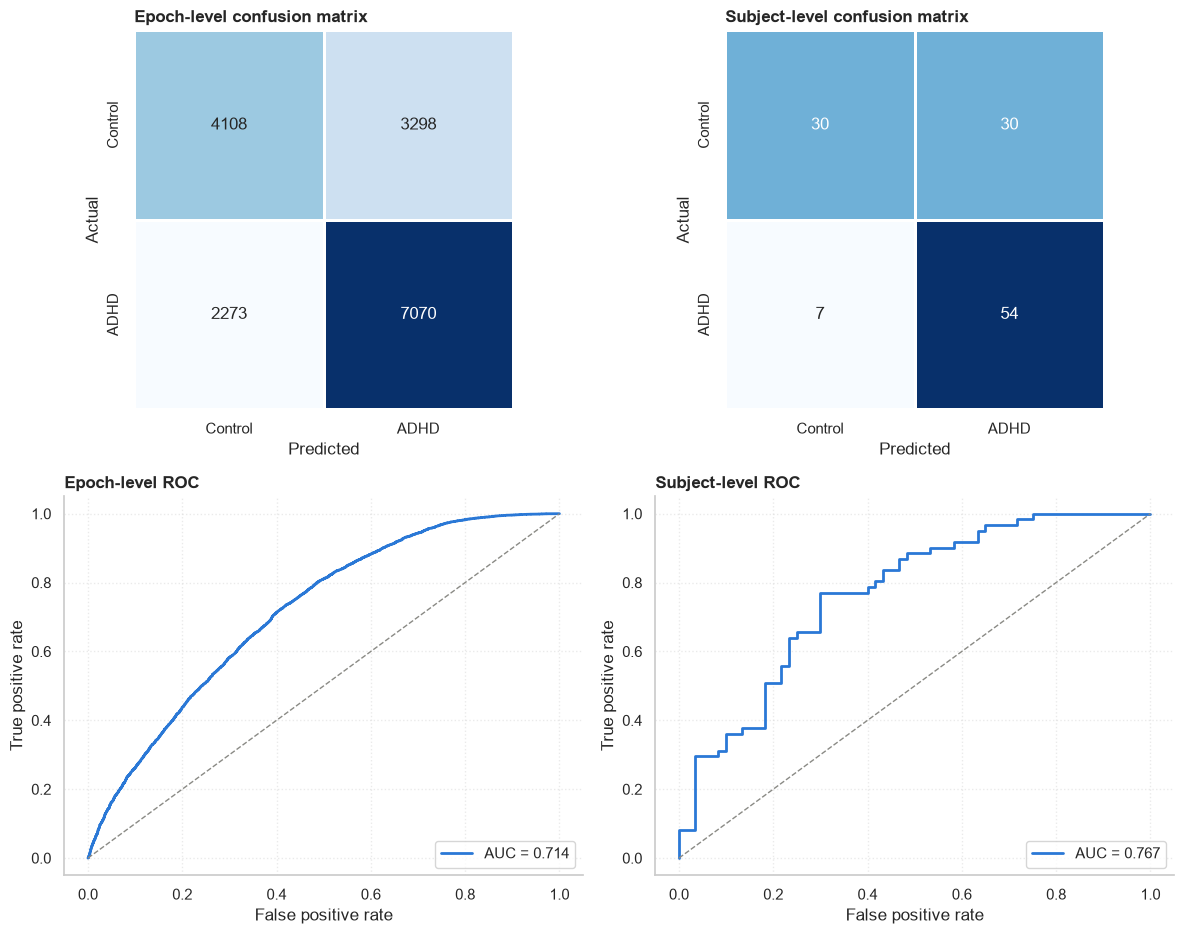

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9.5))
levels = [(oof_y, oof_p, "Epoch"),
          (subject_pred.y_true.values, subject_pred.p_adhd.values, "Subject")]

for col, (yy, pp, lvl) in enumerate(levels):
    cm = confusion_matrix(yy, (pp > 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                linewidths=1, linecolor="white", ax=ax[0, col],
                xticklabels=["Control", "ADHD"], yticklabels=["Control", "ADHD"])
    ax[0, col].set_title("%s-level confusion matrix" % lvl, weight="bold", loc="left")
    ax[0, col].set_xlabel("Predicted"); ax[0, col].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(yy, pp)
    ax[1, col].plot(fpr, tpr, lw=2, color=BLUE, label="AUC = %.3f" % roc_auc_score(yy, pp))
    ax[1, col].plot([0, 1], [0, 1], "--", color="#8a8a85", lw=1)
    ax[1, col].set_title("%s-level ROC" % lvl, weight="bold", loc="left")
    ax[1, col].set_xlabel("False positive rate"); ax[1, col].set_ylabel("True positive rate")
    ax[1, col].legend(loc="lower right"); ax[1, col].grid(alpha=.4, ls=":")
    for sp in ("top", "right"): ax[1, col].spines[sp].set_visible(False)

plt.tight_layout(); plt.show()

## Step 8 - Which features did the forest use?

**What this does.** Averages impurity-based feature importance over the five
fold models and shows the top 20, then sums importance by feature family.

**Two cautions.** Impurity importance favours features with many distinct
values, and - as with the logistic weights - correlated features share credit
unpredictably. The family totals are the robust reading.

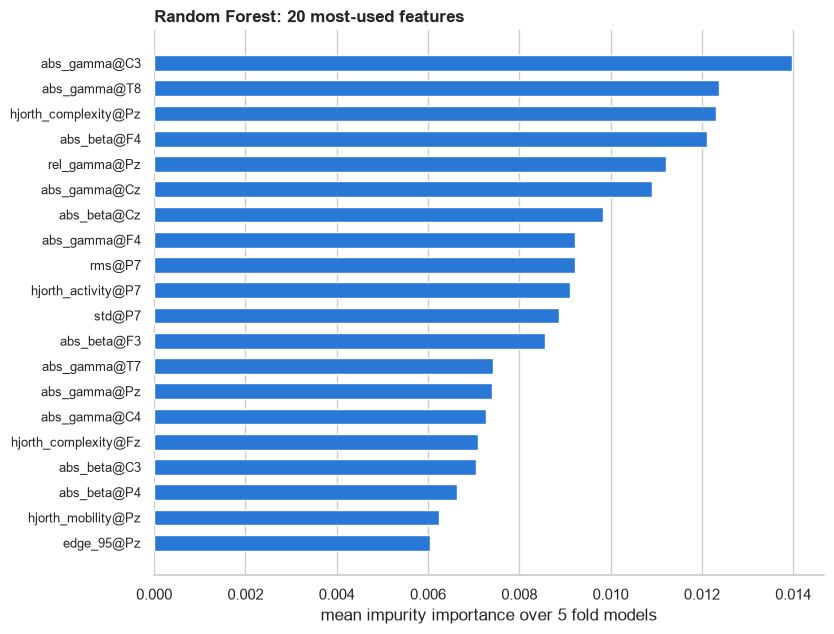

Importance by feature family:
abs_gamma            0.116
abs_beta             0.094
hjorth_complexity    0.078
rms                  0.065
std                  0.065
hjorth_activity      0.064
rel_gamma            0.057
hjorth_mobility      0.052
abs_alpha            0.042
edge_95              0.039


In [9]:
names = cache["feature_names"]
imp = np.zeros(X.shape[1])
for tr, te in cv:
    imp += clone(model).fit(X[tr], y[tr]).feature_importances_
imp = pd.Series(imp / len(cv), index=names)
top = imp.sort_values(ascending=False)[:20]

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.barh(range(len(top))[::-1], top.values, height=.62, color=BLUE)
ax.set_yticks(range(len(top))[::-1], top.index, fontsize=9)
ax.set_xlabel("mean impurity importance over 5 fold models")
ax.set_title("Random Forest: 20 most-used features", weight="bold", loc="left")
ax.grid(axis="y", visible=False)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

fam = imp.groupby([n.split("@")[0] for n in names]).sum().sort_values(ascending=False)
print("Importance by feature family:"); print(fam.head(10).round(3).to_string())

## Step 9 - How much the score moves from fold to fold

**Why this plot is here.** It is the honest picture of uncertainty. Each pair
of bars is one fold - one particular set of ~24 test subjects. The gap between
the best and worst fold is what a single train/test split would have hidden:
the same model, the same code, and a score that depends on which people were
held out.

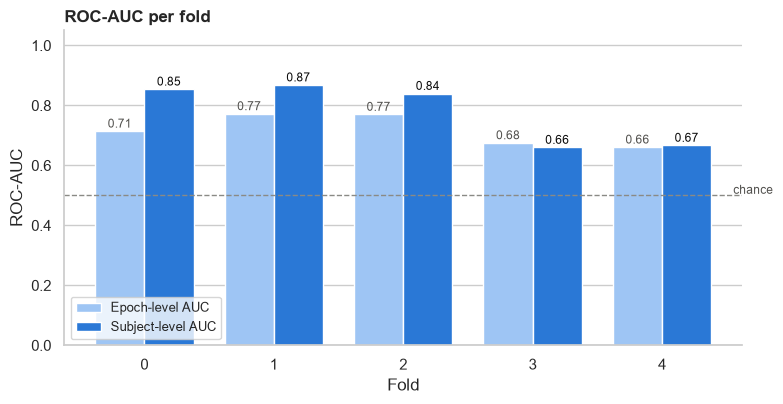

subject-AUC: best fold 0.868, worst fold 0.660, spread 0.208


In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
w = .38
ax.bar(res.fold - w/2, res.epoch_auc, w, color="#9ec5f4", label="Epoch-level AUC")
ax.bar(res.fold + w/2, res.subject_auc, w, color=BLUE, label="Subject-level AUC")
for f, e, s in zip(res.fold, res.epoch_auc, res.subject_auc):
    ax.text(f - w/2, e + .012, "%.2f" % e, ha="center", fontsize=8.5, color=MUTED)
    ax.text(f + w/2, s + .012, "%.2f" % s, ha="center", fontsize=8.5, color=INK)
ax.axhline(.5, ls="--", lw=1, color="#8a8a85"); ax.text(4.55, .505, "chance", fontsize=8.5, color=MUTED)
ax.set_ylim(0, 1.05); ax.set_xticks(res.fold); ax.set_xlabel("Fold"); ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC per fold", weight="bold", loc="left")
ax.legend(loc="lower left", fontsize=9); ax.grid(axis="x", visible=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print("subject-AUC: best fold %.3f, worst fold %.3f, spread %.3f"
      % (res.subject_auc.max(), res.subject_auc.min(), res.subject_auc.max() - res.subject_auc.min()))

## How to report this

- Quote the **subject-level** figures **with their +- SD**. With ~24 subjects
  per test fold, one person is worth about 4 percentage points of accuracy, so
  the spread is part of the result.
- Compare against the other stages in `07_Model_Comparison.ipynb`. A model
  whose mean is higher by less than one standard deviation has **not** been
  shown to be better on this data.